# Part Three: AI Audit

For this audit I tested an AI coding assistant on two of my Part One research questions (Question 2 and Question 3) so I could compare how it handled each one.

## Step 1: Setup

**Research Question 2**: Do high draft picks earn more and score more than second round and undrafted players?

**Research Question 3**: Are higher paid players placed on the injured list more often than lower paid players?

**The dataset**: The AI was told about my cleaned file (cleaned_data.csv), which has 540 NBA players from the 2021-22 season. The prompt gave only the file name and column names, not the data itself or any of its values. As I explain in Step 3, the AI's code still used exact values from my data, so it most likely had outside context. 

The relevant columns are:

* draft_round: the round a player was drafted in, stored as text ("1", "2", or "Undrafted")
* draft_number: the overall pick, stored as text (1 to 60, or "Undrafted")
* salary: salary for the season in US dollars
* points: average points per game
* times_injured: number of times a player was placed on the injured list that season, not counting COVID health and safety placements (0 if none)
* minutes and games: average minutes per game and games played
* salary_tier: salary binned into five groups (Under $2.5M up to $30M+)

### What a correct answer looks like (from my Part One analysis)
**Question 2:** Earlier picks earn and score more. Using Spearman correlation with undrafted players set to round 3 and pick 61, draft pick had a correlation of -0.66 with salary and -0.54 with points. Median salary was about $6.35M for first round picks, $2.06M for second round picks and $0.53M for undrafted players. Median points per game were 10.4, 5.8 and 4.0. A correct answer must include all 164 undrafted players.

**Question 3:** Higher paid players were placed on the injured list more often. The Spearman correlation between salary and times injured was 0.46 for all players and 0.33 for players with at least 20 games. Average placements rose from 1.07 for players under $2.5M to 3.32 for players over $30M. Part of this comes from playing time, but even among players with similar minutes, the highest paid third were placed on the injured list more often, although these gaps come from small groups. In the mid minutes group, where every pay group has at least 28 players, the average went from 1.33 placements for the lowest paid third to 2.29 for the highest paid third. A correct answer should account for playing time and not just report one correlation.


### Exact AI Prompt

AI used: Claude.ai

**Prompt 1 (Question 2):**

I have a CSV file called cleaned_data.csv with NBA player data from the 2021-22 season. The columns are: player, year, position, games, minutes, points, rebounds, assists, salary, times_injured, draft_year, draft_round, draft_number, salary_tier. Write Python code using pandas and matplotlib to answer this question: Do high draft picks earn more and score more than second round and undrafted players? Your code must have code that shows table and charts as an output. Only give me code and nothing else.

**Prompt 2 (Question 3), sent as a follow up in the same chat:**

Using the same cleaned_data.csv file, write Python code using pandas and matplotlib to answer this question: Are higher paid players placed on the injured list more often than lower paid players? Your code must have code that shows table and charts as an output. Only give me code and nothing else.

## Step 2: Run the AI's Code

### Question 2: AI response

```python
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('cleaned_data.csv')

def draft_group(row):
    if row['draft_round'] == 'Undrafted':
        return 'Undrafted'
    if row['draft_round'] == '2':
        return '2nd Round'
    if int(row['draft_number']) <= 10:
        return 'Top 10 Pick'
    return 'Picks 11 to 30'

df['draft_group'] = df.apply(draft_group, axis=1)
order = ['Top 10 Pick', 'Picks 11 to 30', '2nd Round', 'Undrafted']

summary = df.groupby('draft_group').agg(
    players=('player', 'count'),
    avg_salary=('salary', 'mean'),
    median_salary=('salary', 'median'),
    avg_points=('points', 'mean'),
    median_points=('points', 'median')
).reindex(order).round(1)
print(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(order, summary['avg_salary'] / 1e6, color='steelblue')
axes[0].set_title('Average Salary by Draft Group')
axes[0].set_ylabel('Salary ($ millions)')
axes[1].bar(order, summary['avg_points'], color='darkorange')
axes[1].set_title('Average Points per Game by Draft Group')
axes[1].set_ylabel('Points per game')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].boxplot([df.loc[df['draft_group'] == g, 'salary'] / 1e6 for g in order])
axes[0].set_xticks(range(1, 5), order)
axes[0].set_title('Salary Distribution by Draft Group')
axes[0].set_ylabel('Salary ($ millions)')
axes[1].boxplot([df.loc[df['draft_group'] == g, 'points'] for g in order])
axes[1].set_xticks(range(1, 5), order)
axes[1].set_title('Points Distribution by Draft Group')
axes[1].set_ylabel('Points per game')
plt.tight_layout()
plt.show()
```


                players  avg_salary  median_salary  avg_points  median_points
draft_group                                                                  
Top 10 Pick         111  15877373.5      9337691.0        13.4           12.4
Picks 11 to 30      138   9984394.4      4641509.0        10.4            9.0
2nd Round           127   5236571.7      2061329.0         6.6            5.8
Undrafted           164   1958909.6       534959.0         4.7            4.0


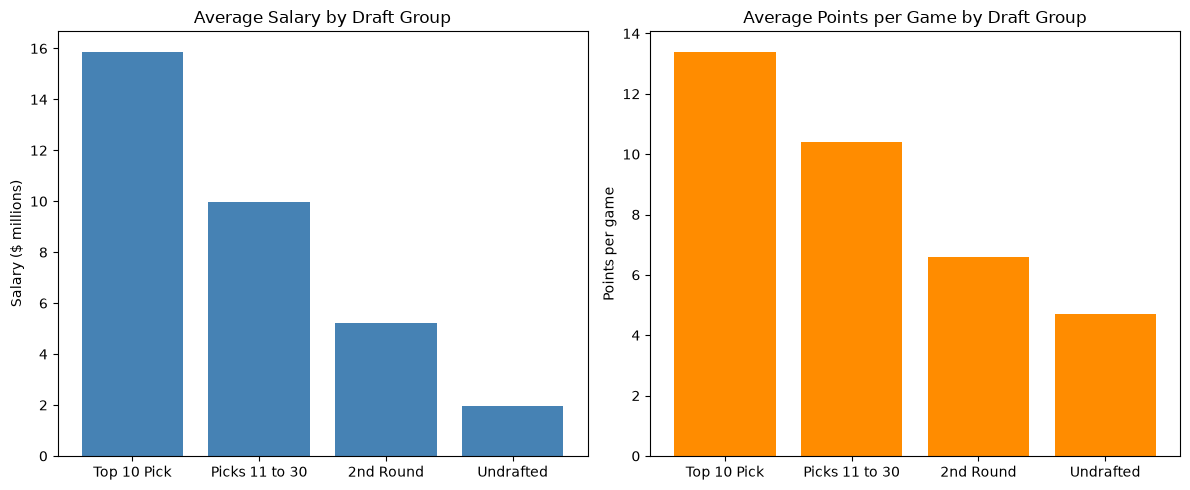

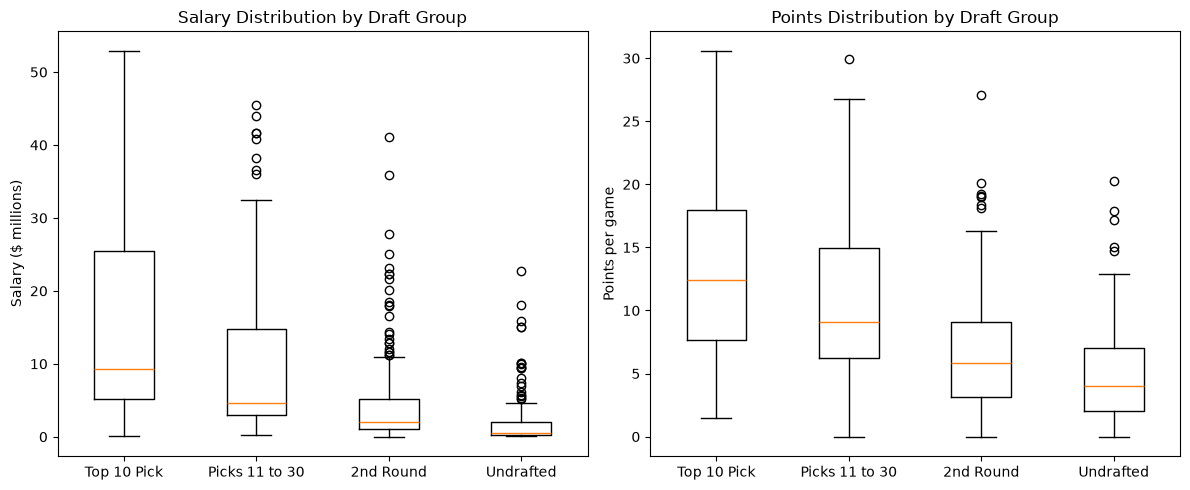

In [1]:
# Question 2: AI's code, run unmodified

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('cleaned_data.csv')

def draft_group(row):
    if row['draft_round'] == 'Undrafted':
        return 'Undrafted'
    if row['draft_round'] == '2':
        return '2nd Round'
    if int(row['draft_number']) <= 10:
        return 'Top 10 Pick'
    return 'Picks 11 to 30'

df['draft_group'] = df.apply(draft_group, axis=1)
order = ['Top 10 Pick', 'Picks 11 to 30', '2nd Round', 'Undrafted']

summary = df.groupby('draft_group').agg(
    players=('player', 'count'),
    avg_salary=('salary', 'mean'),
    median_salary=('salary', 'median'),
    avg_points=('points', 'mean'),
    median_points=('points', 'median')
).reindex(order).round(1)
print(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(order, summary['avg_salary'] / 1e6, color='steelblue')
axes[0].set_title('Average Salary by Draft Group')
axes[0].set_ylabel('Salary ($ millions)')
axes[1].bar(order, summary['avg_points'], color='darkorange')
axes[1].set_title('Average Points per Game by Draft Group')
axes[1].set_ylabel('Points per game')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].boxplot([df.loc[df['draft_group'] == g, 'salary'] / 1e6 for g in order])
axes[0].set_xticks(range(1, 5), order)
axes[0].set_title('Salary Distribution by Draft Group')
axes[0].set_ylabel('Salary ($ millions)')
axes[1].boxplot([df.loc[df['draft_group'] == g, 'points'] for g in order])
axes[1].set_xticks(range(1, 5), order)
axes[1].set_title('Points Distribution by Draft Group')
axes[1].set_ylabel('Points per game')
plt.tight_layout()
plt.show()



### My notes on the Question 2 output

All 540 players are kept (111 + 138 + 127 + 164). The highest first round pick in the data is 30, so the "Picks 11 to 30" label is accurate. The 2nd Round and Undrafted rows match my Part One medians exactly ($2.06M and $0.53M, 5.8 and 4.0 points), and the Top 10 and 11 to 30 rows split my first round median of $6.35M and 10.4 points into two groups. Salary and points both drop steadily from top picks down to undrafted, so the code does answer the question. Every average salary sits well above its median salary, which shows the salary skew, so the bar charts, which plot averages, overstate what a typical player in each group earns. The second bar chart is also orange while the first is blue.


### Question 3: AI response

```python
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('cleaned_data.csv')
order = ['Under $2.5M', '$2.5M to $5M', '$5M to $15M', '$15M to $30M', '$30M+']

summary = df.groupby('salary_tier').agg(
    players=('player', 'count'),
    avg_games=('games', 'mean'),
    avg_times_injured=('times_injured', 'mean'),
    median_times_injured=('times_injured', 'median'),
    pct_injured_at_least_once=('times_injured', lambda x: (x > 0).mean() * 100)
).reindex(order).round(2)
print(summary)
print('Correlation between salary and times injured:', round(df['salary'].corr(df['times_injured']), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(order, summary['avg_times_injured'], color='firebrick')
axes[0].set_title('Average Times Injured by Salary Tier')
axes[0].set_ylabel('Times injured')
axes[1].bar(order, summary['pct_injured_at_least_once'], color='gray')
axes[1].set_title('Percent of Players Injured at Least Once')
axes[1].set_ylabel('Percent of players')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df['salary'] / 1e6, df['times_injured'], alpha=0.5)
plt.title('Salary vs Times Injured')
plt.xlabel('Salary ($ millions)')
plt.ylabel('Times injured')
plt.show()
```


              players  avg_games  avg_times_injured  median_times_injured  \
salary_tier                                                                 
Under $2.5M       252      27.15               1.07                   1.0   
$2.5M to $5M       90      51.93               1.91                   1.0   
$5M to $15M       103      60.12               2.08                   1.0   
$15M to $30M       55      59.22               3.25                   3.0   
$30M+              40      59.65               3.32                   3.0   

              pct_injured_at_least_once  
salary_tier                              
Under $2.5M                       50.79  
$2.5M to $5M                      76.67  
$5M to $15M                       80.58  
$15M to $30M                      90.91  
$30M+                             90.00  
Correlation between salary and times injured: 0.39


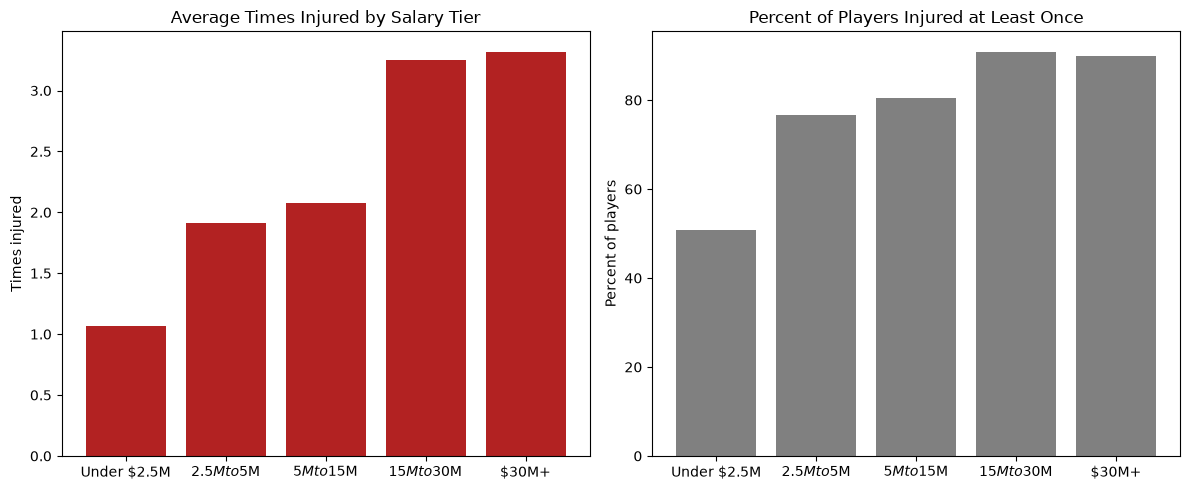

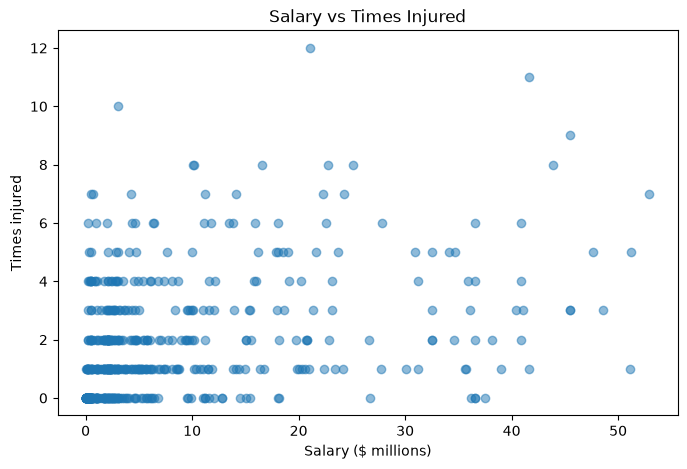

In [2]:
# Question 3: AI's code, run unmodified (only the closing ``` copied from the chat was removed)

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('cleaned_data.csv')
order = ['Under $2.5M', '$2.5M to $5M', '$5M to $15M', '$15M to $30M', '$30M+']

summary = df.groupby('salary_tier').agg(
    players=('player', 'count'),
    avg_games=('games', 'mean'),
    avg_times_injured=('times_injured', 'mean'),
    median_times_injured=('times_injured', 'median'),
    pct_injured_at_least_once=('times_injured', lambda x: (x > 0).mean() * 100)
).reindex(order).round(2)
print(summary)
print('Correlation between salary and times injured:', round(df['salary'].corr(df['times_injured']), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(order, summary['avg_times_injured'], color='firebrick')
axes[0].set_title('Average Times Injured by Salary Tier')
axes[0].set_ylabel('Times injured')
axes[1].bar(order, summary['pct_injured_at_least_once'], color='gray')
axes[1].set_title('Percent of Players Injured at Least Once')
axes[1].set_ylabel('Percent of players')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df['salary'] / 1e6, df['times_injured'], alpha=0.5)
plt.title('Salary vs Times Injured')
plt.xlabel('Salary ($ millions)')
plt.ylabel('Times injured')
plt.show()


### My notes on the Question 3 output

All 540 players are included (252 + 90 + 103 + 55 + 40). The average times injured rises from 1.07 in the lowest tier to 3.32 in the top tier. The share of players injured at least once climbs from about 51% to about 90%, and the median jumps from 1 to 3 once salaries pass $15M. The first figure shows average times injured by tier and the percent of players injured at least once, side by side. The second figure is a scatter plot of salary in millions against times injured, which shows a loose upward pattern, with most low salary players clustered at 0 to 2 injuries.


## Step 3: Evaluation

**1. Did the AI's code run without errors?**

Yes, after one copy fix. The closing ``` from the chat was pasted with the Question 3 code and caused a SyntaxError, so I removed that line and changed nothing else. After that, both cells ran with no errors and produced every table and chart they promised. The Question 2 code avoided a ValueError on the text column `draft_number` by checking `draft_round` for "Undrafted" before calling `int()`, even though my prompt never said undrafted players were stored as text (see question 3). The main display problem was that three of the five salary tier labels on the Question 3 charts came out as garbled math text because of the $ signs (see Step 4).

**2. Correct, partially correct, or wrong? How do I know?**

*Question 2:* Correct but incomplete, since the second round and undrafted medians match my Part One results exactly ($2.06M and 5.8 points; $0.53M and 4.0 points) and all 164 undrafted players were kept. However, it never measured the strength of the relationship (no correlation), so it shows that earlier picks earn and score more but not how strongly draft position predicts either.

*Question 3:* Partially correct, because the tier averages match Part One exactly (1.07 for under $2.5M up to 3.32 for $30M+), and its own table shows only 51% of the lowest tier were placed on the injured list at least once compared to about 90% of the top two tiers, so the direction of the answer is right. But its single correlation of 0.39 differs from my Spearman value of 0.46 because it used Pearson, and it never controlled for playing time even though it added an `avg_games` column showing the lowest tier played about 27 games compared to about 52 to 60 for the others. My Part One analysis suggests a smaller pay gap remains even when playing time is similar (1.33 vs 2.29 placements in the mid minutes group, from groups of 43 and 28 players), which the AI's code cannot show.

**3. Did the AI make wrong assumptions about my data?**

The AI used `.corr()` with its default Pearson setting on salary and times injured, which are both skewed, so a rank based Spearman correlation is the better fit, although both are positive (0.39 vs 0.46). Its bar charts plot mean salary, which star contracts pull upward (top 10 mean $15.9M vs median $9.3M). A subtler risk is that `draft_round == '2'` only works because the "Undrafted" text forces pandas to read the column as strings; if that column were numeric, every second round player would silently fall into "Picks 11 to 30" with no error. The function also assumes `draft_round` and `draft_number` always agree: one undrafted player in the raw draft file (Scotty Hopson) was listed as round 0, pick 0, and without my Part One recode the AI's code would have labeled him a "Top 10 Pick" with no error, because `int('0') <= 10` is true. Similarly, the hard coded tier labels in `order` would silently return NaN rows if any label were spelled differently.

**Note on test conditions:** The most surprising issue is what the AI assumed correctly. My prompt only listed column names, yet the Question 3 code typed out my exact salary tier labels ('Under $2.5M', '$2.5M to $5M' and so on), and the Question 2 code assumed that undrafted players are stored as the text "Undrafted" and draft rounds as text like '2'. The tier labels are very unlikely to be guessed exactly from column names, and the "Undrafted" text may also come from the public Kaggle dataset the AI could have seen in training. Claude.ai can use memory and past chats, and I had discussed this project there before, so it most likely drew on my earlier work. This likely means the test was not fully blind: some of the AI's correct handling of my data probably came from context that was not in the prompt, and a user without that history could get code that crashes on the "Undrafted" text or returns empty tier rows.

**4. Was the code readable and well commented?**

The code was easy to follow because it used clear variable names and named aggregations like `avg_salary` and `pct_injured_at_least_once`. However, there were zero comments in either code cell, so the code itself does not explain why it chose a top 10 cutoff or why it included games played. It also repeated nearly identical plotting lines for each subplot instead of using a loop, and relied on hard coded values like `1e6` and `range(1, 5)`. Six of its seven charts show group names on the x axis but no x axis title (only the salary vs. times injured scatter plot has one).

**5. Would I trust this output if I had not done the analysis myself?**

For Question 2, mostly yes, because the group differences are large and consistent across every measure. For Question 3, not fully: the output looks polished and complete, but its only measure of strength is a single Pearson correlation, and it never separates salary from playing time, which is the most obvious alternative explanation. Without my Part One analysis, I would not have known that Spearman was the better fit for this skewed data or whether the effect survives once minutes are taken into account. This shows the AI can produce code that runs without errors and looks finished while leaving out the step that actually makes the answer defensible.

**Comparing the two tests:** The AI did better on Question 2 than Question 3. Question 2 only needed group summaries, and the groups differ so much that every method I tried gives the same answer. Question 3 needed a judgment call about a confounding variable (playing time) and the better correlation method. The AI used the less suited Pearson correlation and never controlled for playing time, even though its own avg_games column pointed to it. In both cases it wrote clean code with no comments, and nothing in the code explains its choices, such as the top 10 cutoff or why it included games played.

## Step 4: Corrected version

### Question 2: correct but incomplete

**What the AI did well:** It kept all 164 undrafted players, avoided crashing on the "Undrafted" text values, and its medians for second round ($2.06M, 5.8 points) and undrafted players ($0.53M, 4.0 points) matched my Part One results exactly. The direction of its answer was right. Its split of the first round into top 10 picks and picks 11 to 30 was also useful, because it answers "high draft picks" more directly than my round groups did. It shows a clear gap inside the first round: top 10 picks had a median salary of $9.34M and 12.4 points, compared to $4.64M and 9.05 points for picks 11 to 30. I kept this split in my corrected code.

**What I changed and why:**

* **Added Spearman correlation.** The AI only compared group summaries (means, medians and boxplots), so it never measured how strongly draft position relates to pay and scoring. Draft pick has a correlation of -0.66 with salary and -0.54 with points.
* **Used medians instead of means in the charts.** Salary is skewed by star contracts, so the AI's average bars overstate what a typical player earns.
* **Recoded undrafted players as round 3 and pick 61.** The code finds the last real round and pick in the data and adds one, so these are not typed in by hand. This makes the columns true integers and removes the fragile `draft_round == '2'` text comparison, which would silently put every second round player in the wrong group if the column were ever read as numbers.
* **Added official draft rounds next to the AI's groups.** The AI's code uses a top 10 cutoff with no comment explaining it, so I show the medians both by official round and by the AI's four groups. The pick groups are built with `pd.cut()`. The last real pick comes from the data, while the 10 cutoff and the 11 to 30 group come from the AI.
* **Labeled every chart axis.** The AI's Question 2 charts had no x axis labels, so I added them and named the groups First round, Second round and Undrafted.

**Will the AI always get this right?** Probably not. It handled the mixed text and number column this time, most likely because it had context from my past chats (see Step 3), but a slightly different prompt could lead it to call `.astype(int)` on the whole column, which would crash, or to use `pd.to_numeric(errors='coerce')` and `dropna()`, which would silently drop all 164 undrafted players. It also only labeled every player correctly because my cleaned data had already fixed the round 0 player.


,draft_round,draft_number,salary,points
draft_round,1.00,0.94,-0.64,-0.50
draft_number,0.94,1.00,-0.66,-0.54
salary,-0.64,-0.66,1.00,0.74
points,-0.50,-0.54,0.74,1.00


,salary,points
draft_round,,
1,6.35,10.4
2,2.06,5.8
3,0.53,4.0


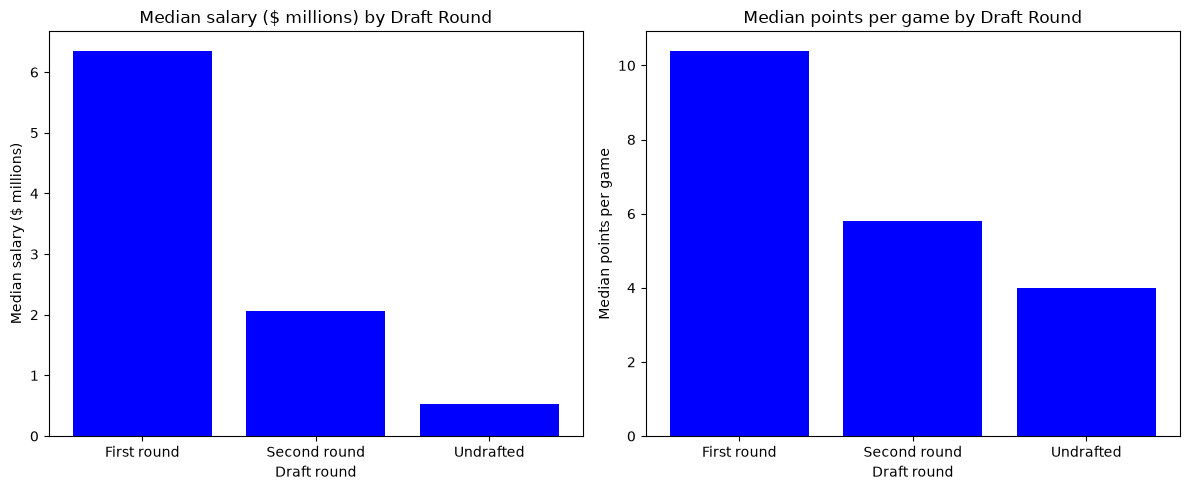

First round: median salary $6.35M, median points 10.4
Second round: median salary $2.06M, median points 5.8
Undrafted: median salary $0.53M, median points 4.0


,salary,points,players
draft_number,,,
Top 10 pick,9.34,12.40,111
Picks 11 to 30,4.64,9.05,138
Second round,2.06,5.80,127
Undrafted,0.53,4.00,164


In [3]:
# Question 2: corrected code
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['text.parse_math'] = False

df = pd.read_csv('cleaned_data.csv', index_col=0)

# undrafted players go after the last real pick and round, found from the data
last_pick = pd.to_numeric(df['draft_number'], errors='coerce').max()
last_round = pd.to_numeric(df['draft_round'], errors='coerce').max()
df['draft_round'] = df['draft_round'].replace('Undrafted', last_round + 1).astype(int)
df['draft_number'] = df['draft_number'].replace('Undrafted', last_pick + 1).astype(int)

# Spearman correlation between draft position, salary and points
display(df[['draft_round', 'draft_number', 'salary', 'points']].corr(method='spearman').round(2))

# median salary (in millions) and points for each round
medians = df.groupby('draft_round')[['salary', 'points']].median()
medians['salary'] = medians['salary'] / 1000000
display(medians.round(2))

round_names = ['First round', 'Second round', 'Undrafted']
labels = ['Median salary ($ millions)', 'Median points per game']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, col in enumerate(['salary', 'points']):
    axes[i].bar(round_names, medians[col], color='blue')
    axes[i].set_title(f'{labels[i]} by Draft Round')
    axes[i].set_xlabel('Draft round')
    axes[i].set_ylabel(labels[i])
plt.tight_layout()
plt.show()

for name, r in zip(round_names, medians.index):
    print(f"{name}: median salary ${medians.loc[r, 'salary']:.2f}M, median points {medians.loc[r, 'points']:.1f}")

# keep the AI's split of the first round, since it shows the gap inside round 1
pick_groups = pd.cut(df['draft_number'], bins=[0, 10, 30, last_pick, last_pick + 1],
                     labels=['Top 10 pick', 'Picks 11 to 30', 'Second round', 'Undrafted'])
group_medians = df.groupby(pick_groups, observed=True)[['salary', 'points']].median()
group_medians['salary'] = group_medians['salary'] / 1000000
group_medians['players'] = df.groupby(pick_groups, observed=True)['salary'].count()
display(group_medians.round(2))

### Question 3: incomplete, with a chart error

**What I changed and why:**

* **Turned off math text for labels.** Matplotlib reads text between two dollar signs as a math formula, so the AI's labels like "$2.5M to $5M" displayed as italic "2.5Mto5M". I added `plt.rcParams['text.parse_math'] = False`, the same fix I used in Part Two, so salary tier labels display correctly whenever they are plotted. My corrected chart below uses minutes and pay groups instead, so it has no dollar signs.
* **Switched from Pearson to Spearman.** The AI used `.corr()` with its default Pearson method, which is less suited to skewed data like salary. Spearman gives 0.46 instead of 0.39.
* **Removed players with fewer than 20 games.** The AI's own table showed the lowest paid tier averaged only 27 games, so they had fewer chances to be injured. For the 396 regular players, the correlation drops to 0.33.
* **Compared pay groups within the same minutes group.** This is the key step the AI skipped. In every minutes group, higher paid players were placed on the injured list more often. The most reliable comparison is the mid minutes group, where every pay group has at least 28 players and similar average minutes (21.6 to 23.8), and placements went from 1.33 to 2.29. The high minutes group shows a bigger gap (1.62 to 3.45), but only 8 players were in its low pay group, so that average is less reliable. In the low minutes group, the highest paid players still averaged 16.0 minutes compared to 12.0 for the lowest paid, so part of that gap may come from playing time. These groups are small and I did not test whether the gaps are statistically significant, so this suggests rather than proves that pay matters beyond playing time.
* **Built the groups from the data.** I used `pd.qcut()` to split players into thirds, so the code does not depend on typing every salary tier label exactly like the AI's `order` list.

**Cleaner code:** I used one pandas bar chart instead of repeating plot lines for each subplot, saved the pivot tables as variables so they are reused instead of recalculated, and used a loop with f-strings so the printed summary is generated from the data.


All players: 540


,times_injured,salary,games,minutes
times_injured,1.00,0.46,0.24,0.36
salary,0.46,1.00,0.66,0.73
games,0.24,0.66,1.00,0.68
minutes,0.36,0.73,0.68,1.00


Players with 20+ games: 396


,times_injured,salary,games,minutes
times_injured,1.00,0.33,-0.06,0.33
salary,0.33,1.00,0.32,0.69
games,-0.06,0.32,1.00,0.53
minutes,0.33,0.69,0.53,1.00


pay_group,Low pay,Mid pay,High pay
minutes_group,,,
Low minutes,1.30,1.65,2.09
Mid minutes,1.33,1.84,2.29
High minutes,1.62,2.39,3.45


pay_group,Low pay,Mid pay,High pay
minutes_group,,,
Low minutes,81,40,11
Mid minutes,43,61,28
High minutes,8,31,93


pay_group,Low pay,Mid pay,High pay
minutes_group,,,
Low minutes,12.0,12.9,16.0
Mid minutes,21.6,21.7,23.8
High minutes,30.0,31.3,32.3


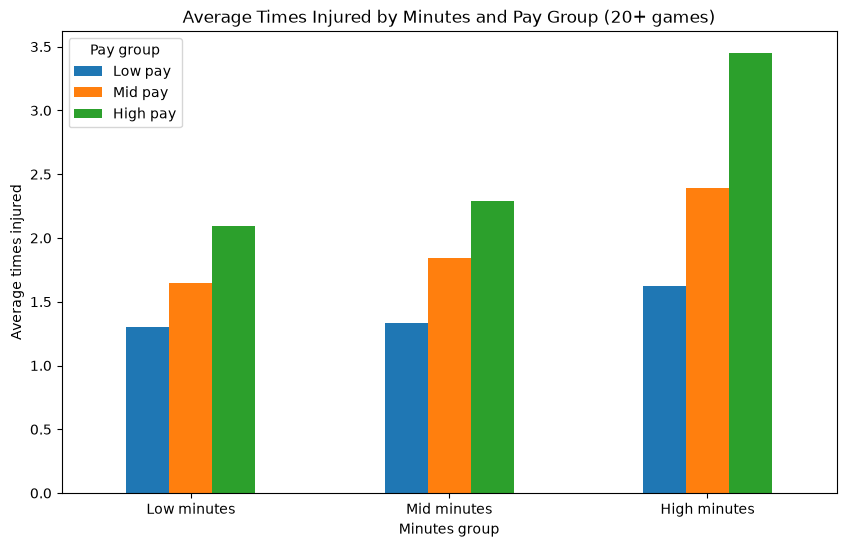

Low minutes: 1.3 for Low pay (81 players) vs 2.09 for High pay (11 players)
Mid minutes: 1.33 for Low pay (43 players) vs 2.29 for High pay (28 players)
High minutes: 1.62 for Low pay (8 players) vs 3.45 for High pay (93 players)


In [4]:
# Question 3: corrected code
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['text.parse_math'] = False

df = pd.read_csv('cleaned_data.csv', index_col=0)
cols = ['times_injured', 'salary', 'games', 'minutes']
min_games = 20

# Spearman correlation for all players
print(f"All players: {len(df)}")
display(df[cols].corr(method='spearman').round(2))

# keep players with at least min_games games so everyone had a real chance to be injured
regulars = df[df['games'] >= min_games].copy()
print(f"Players with {min_games}+ games: {len(regulars)}")
display(regulars[cols].corr(method='spearman').round(2))

# split into thirds by minutes and by salary, then compare at similar playing time
regulars['minutes_group'] = pd.qcut(regulars['minutes'], 3, labels=['Low minutes', 'Mid minutes', 'High minutes'])
regulars['pay_group'] = pd.qcut(regulars['salary'], 3, labels=['Low pay', 'Mid pay', 'High pay'])
averages = regulars.pivot_table(index='minutes_group', columns='pay_group', values='times_injured', aggfunc='mean', observed=True).round(2)
counts = regulars.pivot_table(index='minutes_group', columns='pay_group', values='times_injured', aggfunc='count', observed=True)
display(averages)
display(counts)

# average minutes in each group, to check how similar the playing time really is
display(regulars.pivot_table(index='minutes_group', columns='pay_group', values='minutes', aggfunc='mean', observed=True).round(1))

averages.plot(kind='bar', figsize=(10, 6))
plt.title(f'Average Times Injured by Minutes and Pay Group ({min_games}+ games)')
plt.xlabel('Minutes group')
plt.ylabel('Average times injured')
plt.xticks(rotation=0)
plt.legend(title='Pay group')
plt.show()

for group in averages.index:
    low = averages.columns[0]
    high = averages.columns[-1]
    print(f"{group}: {averages.loc[group, low]} for {low} ({counts.loc[group, low]} players) vs {averages.loc[group, high]} for {high} ({counts.loc[group, high]} players)")